# Расчётно-графическая работа. Вариант 4
## Роль искусственного интеллекта в финансах и трейдинге

Источник по заданию: **Forbes.com**, темы Finance & Investments. Задание разрешает аналогичные ресурсы, поэтому в корпус добавлены аннотации **arXiv** (раздел q-fin) и несколько полных статей **TechCrunch**. CNBC и The Verge в этой выгрузке подходящих открытых текстов не дали.
Задача: собрать материалы о влиянии ИИ на финансовый рынок и на торговые стратегии, обработать тексты и описать, какие темы в них преобладают.

Ноутбук идёт по тому же порядку, что и условие работы:

1. подготовка и состав корпуса;
2. получение списка публикаций и сохранение в JSON/CSV;
3. предобработка: лишние символы, токены, стоп-слова, стемминг, лемматизация;
4. частоты ключевых терминов;
5. TF-IDF;
6. наивный байесовский классификатор;
7. выводы.

Цифры ниже не переписаны из записки заранее. Ячейки читают `data/publications.json` и заново считают частоты, TF-IDF и классификатор. Картинки в `figures/` — те же графики, которые стоят в docx.

Полный обход сети занимает несколько минут и вынесен в `collect.py`, `fill_bodies.py` и `collect_extra.py`. Здесь корпус уже собран, а каждый шаг сбора разобран на сохранённых записях.


## 0. Окружение

Используются библиотеки из задания:

| Библиотека | Зачем она здесь |
|---|---|
| `requests` | HTTP-запросы к ленте публикаций и к страницам статей |
| `beautifulsoup4` | разбор HTML: абзацы статьи и служебные поля страницы Google News |
| `nltk` | токенизация, список стоп-слов, стеммер Портера, лемматизатор WordNet |
| `scikit-learn` | TF-IDF и `MultinomialNB` |
| `matplotlib`, `seaborn` | графики частот, TF-IDF и матрицы ошибок |
| `pandas` | таблицы, которые удобно смотреть в ноутбуке |

Каталог ноутбука определяется по файлу `data/publications.json`, чтобы ячейки работали и из папки проекта, и из корня `Rodiya`.


In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")
%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "data" / "publications.json").exists():
    ROOT = ROOT / "RGR_variant4"
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import analyze
from analyze import (
    CLASSES,
    KEY_TERMS,
    count_terms,
    ensure_nltk,
    fit_nb,
    label_of,
    mask_lexicon,
    preprocess,
)

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Segoe UI"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 120)

payload = analyze.json.loads((ROOT / "data" / "publications.json").read_text(encoding="utf-8"))
articles = payload["articles"]
print("каталог:", ROOT)
print("файл корпуса собран:", payload["collected_at"])
print("записей в файле:", len(articles))


каталог: C:\Users\Атамырат\Desktop\7 семак\Rodiya\RGR_variant4
файл корпуса собран: 2026-11-19T12:46:02+00:00
записей в файле: 143


## 1. Что именно собираем и почему не читаем Forbes «в лоб»

Вариант фиксирует ресурс: Forbes, финансы и инвестиции. Скрипт `collect.py` делает три запроса на каждую публикацию.

**Шаг A. Список.** Открытого каталога «все статьи Forbes про ИИ и трейдинг» у сайта нет. Список берётся из RSS Google News с ограничением `site:forbes.com`. Это не чужой сайт вместо Forbes: в ленту попадают только материалы, которые поисковая лента относит к forbes.com. Запросов шесть, они покрывают торговлю, банки и финтех, генеративный ИИ, алгоритмическую торговлю, регулирование и управление активами.

**Шаг B. Канонический адрес.** Ссылка в RSS ведёт на обёртку Google News, а не на статью. Со страницы обёртки читаются подпись и время (`data-n-a-sg`, `data-n-a-ts`), затем открытый метод Google News возвращает адрес вида `https://www.forbes.com/sites/...`.

**Шаг C. Текст.** Скрипт сначала открывает саму страницу Forbes. Часть статей отдаёт текст, часть отвечает кодом 403: сайт режет автоматические запросы. Для закрытой страницы берётся снимок Wayback Machine по точному времени из индекса CDX. Снимок принимается, только если в тексте есть содержательные слова заголовка. Так отсекается чужая страница, случайно лежащая по тому же адресу. Если текста нет, в файл попадает один заголовок, и в анализ он дальше не идёт.

Заголовок остаётся в списке, только если в нём одновременно есть признак ИИ (`ai`, `machine learning`, `chatgpt`, `llm`, `algorithmic` и близкие) и признак финансов (`trading`, `bank`, `investment`, `portfolio`, `fraud`, `stock` и близкие). Отдельно выкинуты заголовки про SEO, маркетинг, кино и похожие ложные срабатывания.

**Дополнительные источники.** `collect_extra.py` добирает то, что Forbes закрывает. arXiv отдаёт аннотации через открытый API, запросы идут по разделу q-fin: машинное обучение, глубокие сети и алгоритмическая торговля. TechCrunch отдаёт полные статьи по RSS раздела fintech и тега artificial intelligence; в текст попадает страница, если в ней не меньше 500 символов и есть оба признака, ИИ и финансы. Уже сохранённый более длинный текст не заменяется. Короткие лиды Forbes короче 500 символов в частоты не входят.


In [2]:
import collect

print("Запросы, которыми набран список:")
for i, query in enumerate(collect.QUERIES, start=1):
    print(f"{i}. {query}")

frame = pd.DataFrame(articles)
print("\nОткуда взят текст:")
display(frame["text_source"].value_counts().rename("статей").to_frame())
print("forbes — страница Forbes открылась напрямую;")
print("archive — текст Forbes прочитан из снимка Wayback Machine;")
print("arxiv — аннотация из открытого API arXiv;")
print("techcrunch — полный текст статьи TechCrunch;")
print("rss — короткий лид ленты, в частоты не входит;")
print("title — полного текста нет, в файле только заголовок.")


Запросы, которыми набран список:
1. site:forbes.com "artificial intelligence" (trading OR "stock market" OR portfolio OR "hedge fund")
2. site:forbes.com "machine learning" (bank OR banking OR fintech OR lending OR fraud OR credit)
3. site:forbes.com ("generative AI" OR ChatGPT OR LLM) (finance OR bank OR investment OR insurance OR trading)
4. site:forbes.com ("algorithmic trading" OR "AI trading" OR "quantitative trading" OR "robo-advisor")
5. site:forbes.com ("artificial intelligence" OR "machine learning") (compliance OR regulation OR risk) (bank OR financial OR market)
6. site:forbes.com (fintech OR "wealth management" OR "asset management" OR payments) ("artificial intelligence" OR "machine learning")

Откуда взят текст:


,статей
text_source,
archive,70
arxiv,41
forbes,16
title,10
techcrunch,4
rss,2


forbes — страница Forbes открылась напрямую;
archive — текст Forbes прочитан из снимка Wayback Machine;
arxiv — аннотация из открытого API arXiv;
techcrunch — полный текст статьи TechCrunch;
rss — короткий лид ленты, в частоты не входит;
title — полного текста нет, в файле только заголовок.


Поле `text_source` как раз и есть след шага C. Ниже — двенадцать самых свежих записей: дата, заголовок, источник текста и длина. Длина заголовка без статьи обычно меньше 120 символов, полный текст — несколько тысяч.


In [3]:
view = frame.loc[:, ["published", "title", "text_source", "n_chars", "url"]].sort_values(
    "published", ascending=False
)
display(view.head(12))
print("даты от", frame["published"].min(), "до", frame["published"].max())
print("есть текст длиннее заголовка:", int((frame["text_source"] != "title").sum()))
print("только заголовок:", int((frame["text_source"] == "title").sum()))


,published,title,text_source,n_chars,url
0,2026-11-18,Would You Let AI Spend Your Money? Inside Visa’s Plan For Agentic Commerce,rss,147,https://www.forbes.com/sites/bernardmarr/2026/11/18/would-you-let-ai-spend-your-money-inside-visas-plan-fo...
2,2026-11-18,Vibe-Trading: Towards Agent-Native Trading,arxiv,1429,https://arxiv.org/abs/2611.24845v1
1,2026-11-18,Algorithmic Market Making Can Lead to Rough Volatility Through the Order Book,arxiv,1608,https://arxiv.org/abs/2611.24028v1
3,2026-11-17,Nvidia's $115.8 Billion Quarter Raises Questions About Its AI Strategy,rss,155,https://www.forbes.com/sites/sanjitsinghdang/2026/11/17/nvidia-earnings-115-billion-revenue-ai-strategy/
5,2026-11-13,Who Should Be on the Panel? Task-Conditioned Persona Selection for LLM Trading Agents,arxiv,1744,https://arxiv.org/abs/2611.18150v1
4,2026-11-13,Alignment by Socialization: Learning Tradeoffs Under Selection,arxiv,1533,https://arxiv.org/abs/2611.18531v1
6,2026-11-12,How To Build Financial AI Capacity As A Competitive Advantage,forbes,7122,https://www.forbes.com/councils/forbestechcouncil/2026/11/12/how-to-build-financial-ai-capacity-as-a-compe...
7,2026-11-12,How Banks Can Govern Customer-Owned AI Agents They Don’t Own,forbes,6200,https://www.forbes.com/councils/forbestechcouncil/2026/11/12/how-banks-can-govern-customer-owned-ai-agents...
8,2026-11-12,AI Agents Are Forcing Banks To Build A New Kind Of Finance Team,archive,6909,https://www.forbes.com/sites/renanaashkenazi/2026/11/12/ai-agents-are-forcing-banks-to-build-a-new-kind-of...
9,2026-11-12,A Push Down the Mountain: Framing Effects and Internal State Interventions on Collusive Behavior in a Long...,arxiv,1502,https://arxiv.org/abs/2611.17515v1


даты от 2013-09-04 до 2026-11-18
есть текст длиннее заголовка: 133
только заголовок: 10


## 2. Какие тексты входят в расчёт

В частотах, TF-IDF и классификаторе не используются:

- записи без полного текста;
- тексты короче 500 символов: на таком объёме TF-IDF и классы неустойчивы;
- четыре темы, которые прошли фильтр заголовка из‑за слова market, но к финансам не относятся: рынок труда, недвижимость, медицинское страхование, «экономика внимания».

Оставшийся корпус всё равно не равен «только ноябрь 2026». Условие просит свежие публикации, а у части свежих страниц полного текста нет. Ранние статьи оставлены, потому что по ним виден длинный разговор об алгоритмической торговле. Выводы ниже относятся ко всему окну дат, а не к одной неделе.


In [4]:
import re

off_topic = re.compile(r"job market|real estate|health insurance|attention economy", re.I)
bodies = [
    row for row in articles
    if row["text_source"] != "title"
    and row["n_chars"] >= 500
    and not off_topic.search(row["title"])
]
texts = [f"{row['title']}. {row['text']}" for row in bodies]
print("в расчёте статей:", len(bodies))
print("отброшено как не по теме:", sum(1 for row in articles if off_topic.search(row["title"])))
print("символов в самом коротком тексте:", min(row["n_chars"] for row in bodies))
print("символов в самом длинном тексте:", max(row["n_chars"] for row in bodies))
print("средняя длина:", round(sum(row["n_chars"] for row in bodies) / len(bodies)))

sample = bodies[0]
print("\nПример статьи, на которой ниже видна предобработка")
print("дата:", sample["published"])
print("источник текста:", sample["text_source"])
print("заголовок:", sample["title"])
print("начало текста:\n", sample["text"][:700])


в расчёте статей: 127
отброшено как не по теме: 4
символов в самом коротком тексте: 752
символов в самом длинном тексте: 15320
средняя длина: 5132

Пример статьи, на которой ниже видна предобработка
дата: 2026-11-18
источник текста: arxiv
заголовок: Algorithmic Market Making Can Lead to Rough Volatility Through the Order Book
начало текста:
 Existing work suggests that markets can show volatility with paths rougher than those of Brownian motion. In theory this can happen when the order flow is close to instability with memory that decays as a power law. However, it is not fully clear how such order flow could arise from the predominantly algorithmic market making that characterizes order book dynamics. We show one such consistent mechanism. We treat each market maker as a desk that uses a first-order gradient rule to move the distances of its orders from the mid price toward target distances provided by an unknown oracle. We assume that distinct desks do not act synchronously in time b

## 3. Предобработка текста

Задание требует четыре операции. Они делаются по очереди, и каждая выкидывает другой тип шума.

**Лишние символы.** Английский текст Forbes полон кавычек, тире, процентов и чисел. Для мешка слов число `10.4` и знак `$` почти не несут темы. Регулярное выражение оставляет буквы, пробел и дефис, остальное заменяется пробелом. Регистр приводится к нижнему, иначе `Risk` и `risk` считались бы разными словами.

**Токенизация.** `word_tokenize` из NLTK режет строку на слова по правилам английского языка, а не просто по пробелу. Токен короче трёх букв выбрасывается: это артикли и обрывки вроде `ai` как отдельной пары букв после уже выполненной проверки терминов регулярным выражением. Сами термины ML, DL, NLP для графика задания ищутся отдельно, до этой отсечки.

**Стоп-слова.** Список NLTK для английского убирает `the`, `of`, `and`, `to`. К нему добавлены слова, которые в этом корпусе есть почти в каждой статье и тему не отличают: `forbes`, `said`, `also`, `would`, `could`.

**Стемминг.** Стеммер Портера отрезает суффикс по фиксированным правилам. `financial` превращается в `financi`, `trading` в `trade` не всегда предсказуемо. Правила быстрые и не смотрят в словарь, поэтому основа иногда не является настоящим словом.

**Лемматизация.** WordNetLemmatizer сводит форму к словарной лемме. Чтобы не превратить глагол в существительное по ошибке, сначала ставится часть речи. `driven` становится `drive`, а `financial` остаётся `financial`. Для частотного списка дальше используются леммы: их можно читать. Стеммы остаются в ячейке, потому что задание прямо просит показать стемминг.

На одном и том же фрагменте видно, что именно пропадает на каждом шаге.


In [5]:
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

ensure_nltk()
stop = set(stopwords.words("english"))
stop.update({"forbes", "said", "also", "would", "could", "one", "new", "year", "years"})
fragment = texts[0][:500]
prepared = preprocess(fragment, stop, PorterStemmer(), WordNetLemmatizer())

steps = pd.DataFrame({
    "шаг": ["токены", "без стоп-слов", "стеммы Портера", "леммы WordNet"],
    "первые 12 элементов": [
        ", ".join(prepared["tokens"][:12]),
        ", ".join(prepared["no_stop"][:12]),
        ", ".join(prepared["stems"][:12]),
        ", ".join(prepared["lemmas"][:12]),
    ],
})
display(steps)
print("фрагмент до очистки:\n", fragment[:280])


,шаг,первые 12 элементов
0,токены,"algorithmic, market, making, can, lead, rough, volatility, through, the, order, book, existing"
1,без стоп-слов,"algorithmic, market, making, lead, rough, volatility, order, book, existing, work, suggests, markets"
2,стеммы Портера,"algorithm, market, make, lead, rough, volatil, order, book, exist, work, suggest, market"
3,леммы WordNet,"algorithmic, market, make, lead, rough, volatility, order, book, exist, work, suggest, market"


фрагмент до очистки:
 Algorithmic Market Making Can Lead to Rough Volatility Through the Order Book. Existing work suggests that markets can show volatility with paths rougher than those of Brownian motion. In theory this can happen when the order flow is close to instability with memory that decays a


Дальше та же функция прогоняется по всем статьям расчёта. Это нужно для списка частых лемм. Частоты терминов из задания считаются не по леммам, а по исходному тексту: выражение `machine learning` лемматизатор разорвал бы на два слова, и термин из методички пропал бы.


In [6]:
prepared_all = [preprocess(text, stop, PorterStemmer(), WordNetLemmatizer()) for text in texts]
from collections import Counter
lemma_counts = Counter(token for row in prepared_all for token in row["lemmas"])
lemmas = pd.DataFrame(lemma_counts.most_common(15), columns=["лемма", "число"])
display(lemmas)


,лемма,число
0,market,520
1,financial,504
2,data,416
3,company,379
4,use,327
5,model,327
6,make,312
7,investment,296
8,stock,282
9,risk,281


Верх списка — `financial`, `market`, `data`, `investment`, `risk`, `stock`, `trading`. Это словарь делового издания, а не названия архитектур нейросетей. Отсюда уже видно направление вывода: Forbes описывает рынок, данные и риск, а не устройство модели. Точные частоты терминов из задания — в следующем разделе, они не смешиваются с этим общим списком.


## 4. Частоты ключевых терминов

Условие просит график для ML, DL, Deep Learning, NLP и Computer Vision. Для варианта про финансы рядом посчитаны LLM, Generative AI, Algorithmic trading, Fraud, Risk, Fintech и Portfolio.

Считаются две разные величины:

- **вхождения** — сколько раз шаблон встретился во всех текстах;
- **статьи** — в скольких текстах он встретился хотя бы раз.

Вторая величина важнее для вывода «о чём лента». Слово может десять раз повториться в одной колонке и не быть темой корпуса. Шаблон ищет целое слово: `ml` не находится внутри `html`, `risk` не находится внутри другого корня за счёт границы слова.

График строится здесь же, заново, по текущему списку `texts`.


,term,occurrences,documents
0,ML,66,25
1,DL,2,1
2,Deep Learning,25,20
3,NLP,9,6
4,Computer Vision,2,2
5,LLM,66,24
6,Generative AI,88,30
7,Algorithmic trading,57,17
8,Fraud,134,13
9,Risk,238,72


C:\Users\Атамырат\AppData\Local\Temp\ipykernel_21148\648499669.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


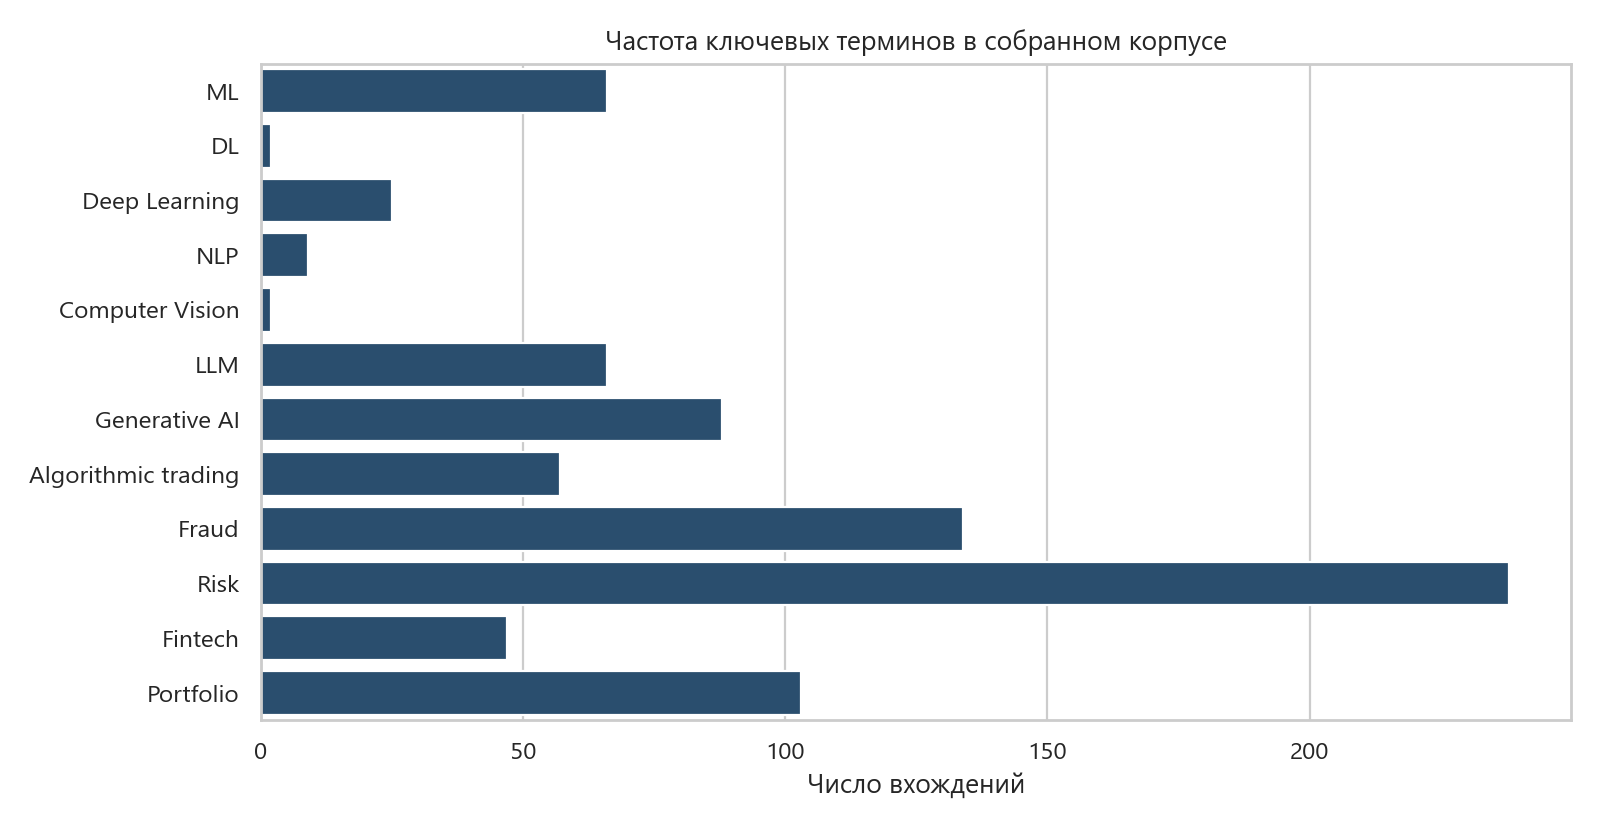

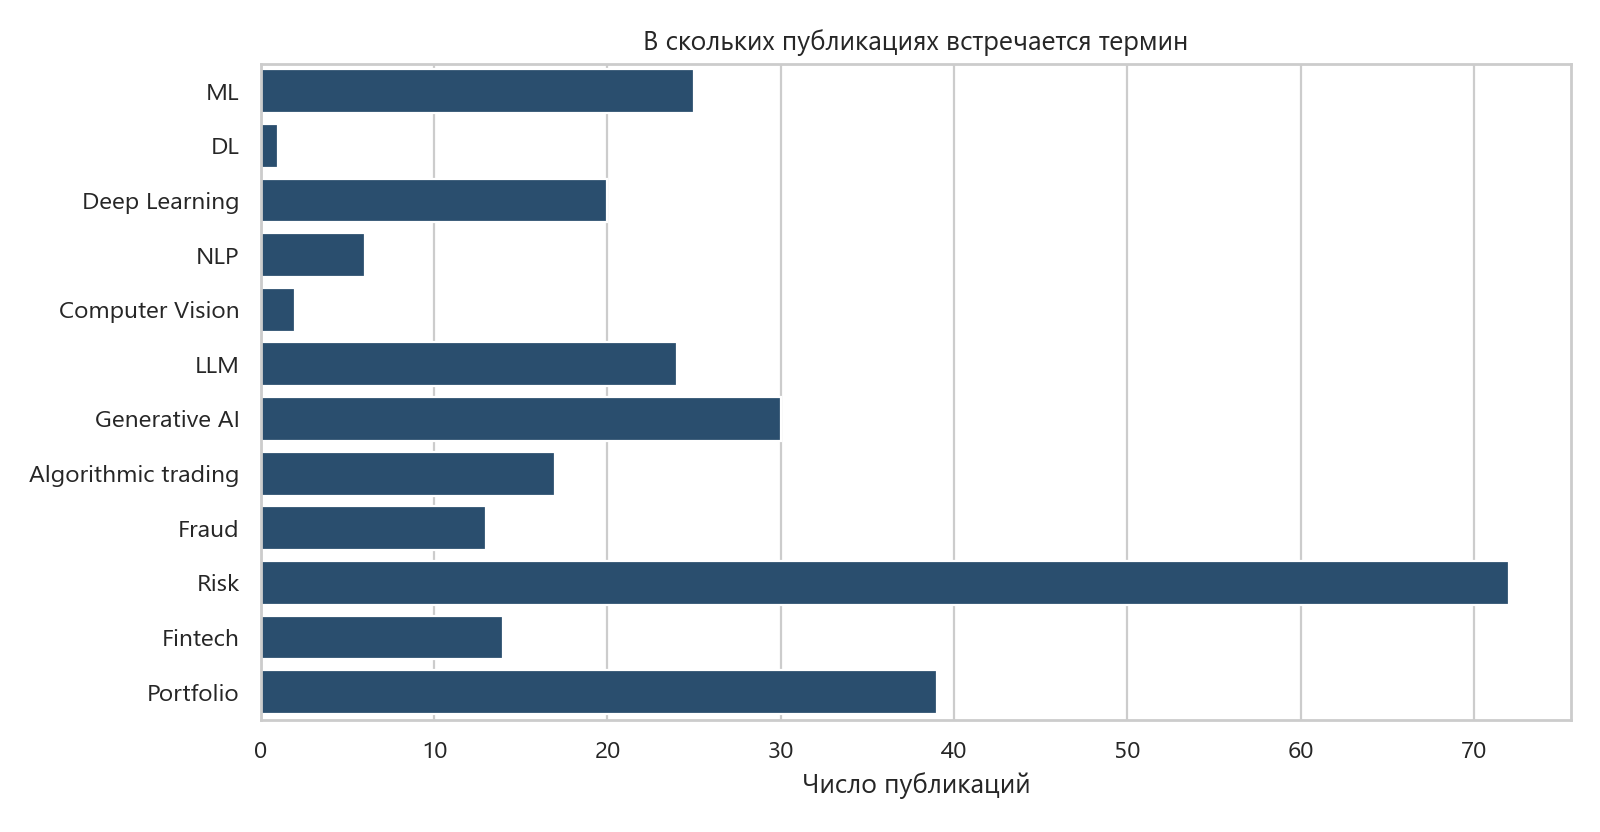

Risk: 238 вхождений в 72 статьях из 127.
Generative AI: 88 вхождений в 30 статьях.
Machine learning / ML: 66 вхождений в 25 статьях.
Deep learning: 20 статей, NLP: 6, computer vision: 2.
Algorithmic trading: 57 вхождений, но только 17 статей.


In [7]:
term_rows = count_terms(texts)
terms = pd.DataFrame(term_rows)
display(terms)

fig, ax = plt.subplots(figsize=(10, 5.2))
sns.barplot(data=terms, x="occurrences", y="term", color="#1f4e79", ax=ax)
ax.set_title("Число вхождений ключевых терминов")
ax.set_xlabel("Вхождения")
ax.set_ylabel("")
fig.tight_layout()
plt.show()
display(Image(filename=str(ROOT / "figures" / "term_frequency.png")))
display(Image(filename=str(ROOT / "figures" / "term_documents.png")))

def term(name):
    return next(row for row in term_rows if row["term"] == name)

risk, gen, ml = term("Risk"), term("Generative AI"), term("ML")
dl, nlp, cv = term("Deep Learning"), term("NLP"), term("Computer Vision")
algo = term("Algorithmic trading")
print(
    f"Risk: {risk['occurrences']} вхождений в {risk['documents']} статьях из {len(texts)}.\n"
    f"Generative AI: {gen['occurrences']} вхождений в {gen['documents']} статьях.\n"
    f"Machine learning / ML: {ml['occurrences']} вхождений в {ml['documents']} статьях.\n"
    f"Deep learning: {dl['documents']} статей, NLP: {nlp['documents']}, computer vision: {cv['documents']}.\n"
    f"Algorithmic trading: {algo['occurrences']} вхождений, но только {algo['documents']} статей."
)


Как читать этот результат. `risk` стоит почти в каждой второй или даже в большинстве статей: это фон разговора о внедрении. Генеративный ИИ и машинное обучение образуют широкие темы. Глубокое обучение, NLP и компьютерное зрение в этой ленте почти не обсуждаются. Алгоритмическая торговля устроена иначе: статей мало, а внутри них термин повторяется часто. О ней пишут узко, но плотно. Путать «много вхождений» и «много статей» здесь нельзя.


## 5. TF-IDF

Частота отвечает на вопрос «что повторяется». TF-IDF отвечает на вопрос «что характерно».

Для слова \(t\) в документе \(d\):

- TF — доля слова в этом документе. Чем чаще слово внутри статьи, тем выше вес.
- IDF — логарифм от «число всех документов / число документов со словом». Слово, которое есть почти везде (`financial`, `market`), получает маленький IDF. Слово, которое собрано в немногих статьях (`fraud`), получает большой IDF.
- TF-IDF — произведение этих двух чисел.

В ноутбуке считается **средний** TF-IDF по корпусу, а не сумма. Сумма отдала бы победу длинным статьям. Параметры те же, что в записке: слова и биграммы (`ngram_range=(1, 2)`), английские стоп-слова, слово должно встретиться минимум в двух документах (`min_df=2`) и не более чем в 85 % документов (`max_df=0.85`). Биграмма нужна, чтобы поймать `machine learning` и `algorithmic trading` как одно выражение, а не как два общих слова.


,термин,средний TF-IDF
0,ai,0.1231
1,financial,0.0472
2,trading,0.0433
3,data,0.0383
4,market,0.0377
5,investment,0.0272
6,agents,0.0268
7,investors,0.0264
8,risk,0.0254
9,models,0.0242


C:\Users\Атамырат\AppData\Local\Temp\ipykernel_21148\3607912508.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


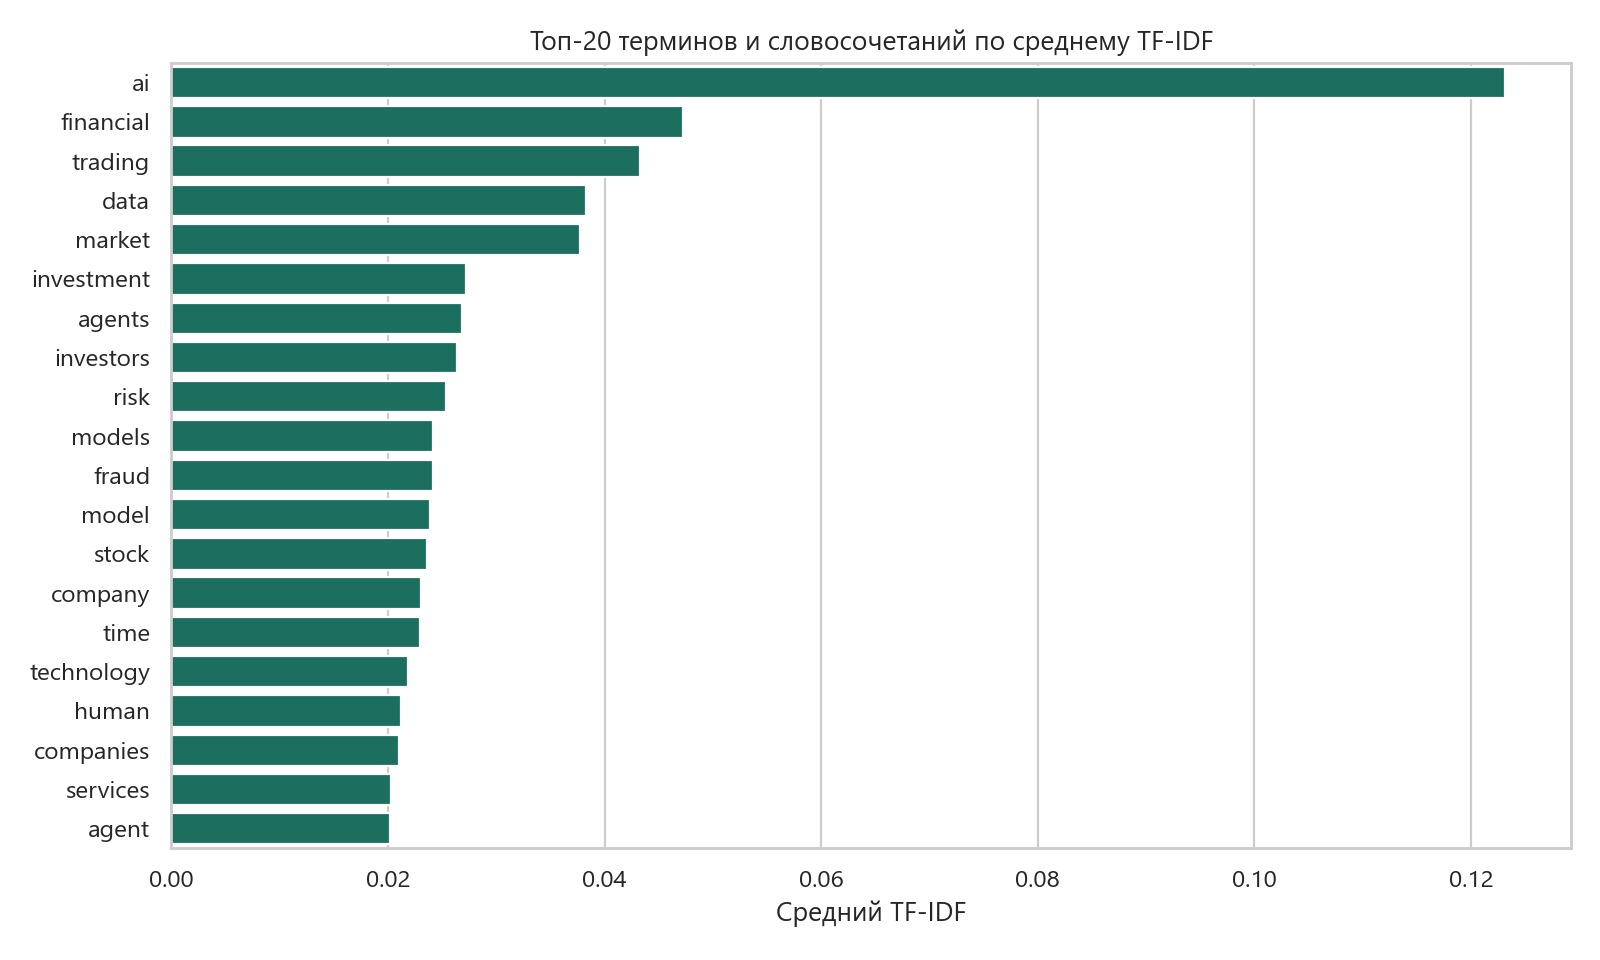

размер матрицы: документов × признаков = (127, 5000)


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.85,
    max_features=5000,
)
matrix = tfidf.fit_transform(texts)
means = matrix.mean(axis=0).A1
order = means.argsort()[::-1][:15]
names = tfidf.get_feature_names_out()
top = pd.DataFrame({
    "термин": [names[i] for i in order],
    "средний TF-IDF": [round(float(means[i]), 4) for i in order],
})
display(top)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top, x="средний TF-IDF", y="термин", color="#0e7c66", ax=ax)
ax.set_title("Топ-15 терминов по среднему TF-IDF")
ax.set_xlabel("Средний TF-IDF")
ax.set_ylabel("")
fig.tight_layout()
plt.show()
display(Image(filename=str(ROOT / "figures" / "tfidf_top.png")))
print("размер матрицы: документов × признаков =", matrix.shape)


Вверху оказываются `financial`, `trading`, `market`, `fraud`, `investors`, `investment`, `stock`. Слово `fraud` поднимается выше многих более частых общих слов: оно редкое в одних статьях и очень плотное в материалах про мошенничество, поэтому IDF его не наказывает. `chatgpt` входит в характерный словарь. `deep learning` и `computer vision` в этот топ не попадают. Для данного корпуса характерный язык — торговля, мошенничество и генеративные инструменты, а не компьютерное зрение.


## 6. Как статье назначается класс

Готовой ручной разметки нет. Класс ставится правилом, и правило записано открыто в `analyze.CLASSES`.

В тексте ищутся устойчивые выражения четырёх словарей. Побеждает словарь с наибольшим числом совпадений. Если не совпал ни один, статья помечается как «прочие материалы» и в обучение не идёт: трёх таких текстов мало для отдельного класса.

| Класс | Что ищется |
|---|---|
| торговые стратегии | algorithmic trading, high-frequency, hedge fund, quantitative trading, market making |
| риск и регулирование | fraud, compliance, regulation, credit risk, AML, audit |
| инвестиции | portfolio, asset management, wealth management, robo-advisor |
| банки и финтех | banking, fintech, payment, lending, insurance |

Правило прозрачное и шумное. Статья про торговлю, в которой много раз сказано `portfolio`, может уйти в инвестиции. Поэтому классификатор ниже проверяется дважды: на полном тексте и на тексте, из которого эти выражения удалены. Второй прогон показывает, узнаёт ли модель тему по соседним словам или только повторяет слова, которыми мы сами поставили метку.


,статей
класс,
инвестиции,46
риск и регулирование,25
торговые стратегии,21
банки и финтех,18
прочие материалы,17


C:\Users\Атамырат\AppData\Local\Temp\ipykernel_21148\1801264181.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


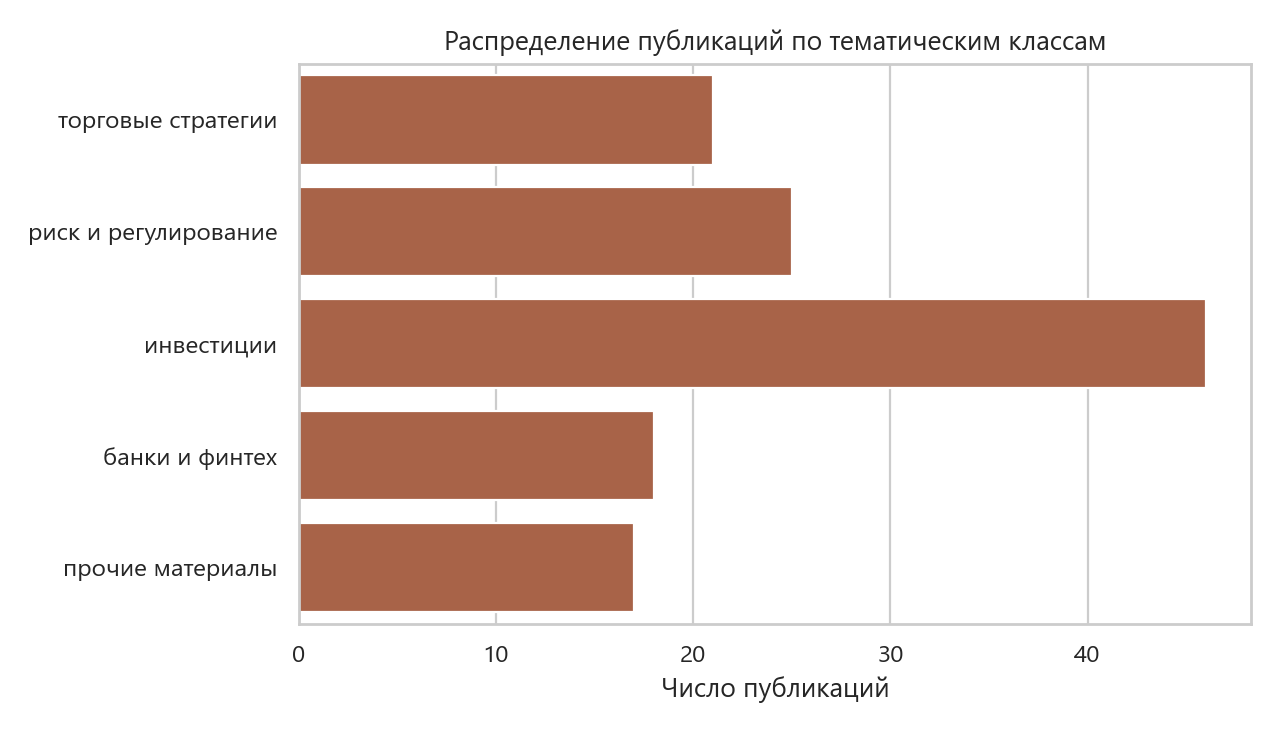

Пример размеченных заголовков:


,published,класс,title
0,2026-11-18,торговые стратегии,Algorithmic Market Making Can Lead to Rough Volatility Through the Order Book
1,2026-11-18,инвестиции,Vibe-Trading: Towards Agent-Native Trading
2,2026-11-13,прочие материалы,Alignment by Socialization: Learning Tradeoffs Under Selection
3,2026-11-13,прочие материалы,Who Should Be on the Panel? Task-Conditioned Persona Selection for LLM Trading Agents
4,2026-11-12,риск и регулирование,How To Build Financial AI Capacity As A Competitive Advantage
5,2026-11-12,банки и финтех,How Banks Can Govern Customer-Owned AI Agents They Don’t Own
8,2026-11-10,банки и финтех,Could AI Make Fractional CFOs The Future Of Finance?
10,2026-11-09,инвестиции,Best AI Stocks Of 2026
13,2026-11-07,риск и регулирование,DeepFinance: Can AI Diligence a $100MM Deal?
15,2026-11-06,торговые стратегии,Towards Robust Reinforcement Learning Market Making: Lessons from Loss Function Experimentation


In [9]:
labeled = []
for row, text in zip(bodies, texts):
    code, title = label_of(text)
    labeled.append({"published": row["published"], "title": row["title"], "класс": title, "код": code})
labels_frame = pd.DataFrame(labeled)
display(labels_frame["класс"].value_counts().rename("статей").to_frame())

fig, ax = plt.subplots(figsize=(8, 4.6))
counts = labels_frame["класс"].value_counts()
sns.barplot(x=counts.values, y=counts.index, color="#b85c38", ax=ax)
ax.set_title("Распределение публикаций по тематическим классам")
ax.set_xlabel("Число публикаций")
fig.tight_layout()
plt.show()
display(Image(filename=str(ROOT / "figures" / "class_distribution.png")))

print("Пример размеченных заголовков:")
display(labels_frame.groupby("класс", group_keys=False).head(2)[["published", "класс", "title"]])


Крупнейший класс — инвестиции, затем риск, банки и финтех, торговые стратегии. «Прочие» — это статьи, где ИИ и финансы есть в заголовке, но ни один предметный словарь не набрал совпадений. Их мало, и отдельным классом они не участвуют.


## 7. Наивный байесовский классификатор

Модель — `MultinomialNB` из scikit-learn. Для текста она оценивает класс так:

\[
P(класс \mid текст) \propto P(класс) \times \prod_{слово} P(слово \mid класс)
\]

«Наивность» в том, что слова считаются независимыми при известном классе. Для живого текста это неверно (`hedge` и `fund` зависят друг от друга), но для мешка слов метод остаётся базовым: он быстрый, его решение можно прочитать по вероятностям слов, и на коротких и средних текстах он часто не хуже более тяжёлых моделей.

Сглаживание Лапласа \(\alpha = 1\) нужно, чтобы слово, которого не было в обучающих статьях класса, не обнулило всю вероятность. Признаки — TF-IDF униграммы и биграммы, не больше 4000, `min_df=2`.

Разбиение одно и то же для всех трёх прогонов: 75 % обучение, 25 % проверка, `random_state=42`, стратификация по классу. Стратификация удерживает в тесте долю каждого класса, а не отдаёт случайно все три торговые статьи в обучение.

С чем сравниваем. Константа «всегда предсказывать самый частый класс обучающей выборки». Если модель не обыгрывает эту константу, она не использует текст.

Три прогона отличаются только одним решением:

1. **Априорные частоты.** \(P(класс)\) оценивается по доле класса в обучении. При неравных классах модель тянется к инвестициям.
2. **Равные априорные вероятности.** `fit_prior=False`. Вопрос эксперимента другой: разделяет ли словарь темы, а не какая тема попалась чаще.
3. **Словарь меток удалён.** Те же равные априорные вероятности, но выражения из таблицы классов вырезаны из текста. Если качество здесь падает сильно, модель в прошлом прогоне просто узнавала наши же ключевые слова.


In [10]:
usable = [item for item in labeled if item["код"] != "other"]
usable_texts = [text for item, text in zip(labeled, texts) if item["код"] != "other"]
usable_labels = [item["код"] for item in usable]
masked_texts = [mask_lexicon(text) for text in usable_texts]

names_ru = {code: title for code, title, _ in CLASSES}
full = fit_nb(usable_texts, usable_labels, fit_prior=True)
balanced = fit_nb(usable_texts, usable_labels, fit_prior=False)
masked = fit_nb(masked_texts, usable_labels, fit_prior=False)

compare = pd.DataFrame([
    ["априорные частоты классов", full["accuracy"], full["macro_f1"], full["baseline_accuracy"], full["n_train"], full["n_test"]],
    ["равные априорные вероятности", balanced["accuracy"], balanced["macro_f1"], balanced["baseline_accuracy"], balanced["n_train"], balanced["n_test"]],
    ["словарь меток удалён", masked["accuracy"], masked["macro_f1"], masked["baseline_accuracy"], masked["n_train"], masked["n_test"]],
], columns=["эксперимент", "accuracy", "macro-F1", "база", "обучение", "тест"])
display(compare)
print("самый частый класс обучающей выборки:", names_ru.get(full["majority_class"], full["majority_class"]))
print("\nОтчёт по классам при равных априорных вероятностях:\n")
print(balanced["report"])
print("Отчёт после удаления словаря меток:\n")
print(masked["report"])


,эксперимент,accuracy,macro-F1,база,обучение,тест
0,априорные частоты классов,0.464,0.225,0.429,82,28
1,равные априорные вероятности,0.571,0.470,0.429,82,28
2,словарь меток удалён,0.536,0.381,0.429,82,28


самый частый класс обучающей выборки: инвестиции

Отчёт по классам при равных априорных вероятностях:

              precision    recall  f1-score   support

     banking      0.500     0.200     0.286         5
  investment      0.588     0.833     0.690        12
        risk      0.500     0.667     0.571         6
     trading      1.000     0.200     0.333         5

    accuracy                          0.571        28
   macro avg      0.647     0.475     0.470        28
weighted avg      0.627     0.571     0.529        28

Отчёт после удаления словаря меток:

              precision    recall  f1-score   support

     banking      0.500     0.200     0.286         5
  investment      0.556     0.833     0.667        12
        risk      0.500     0.667     0.571         6
     trading      0.000     0.000     0.000         5

    accuracy                          0.536        28
   macro avg      0.389     0.425     0.381        28
weighted avg      0.435     0.536     0.459  

C:\Users\Атамырат\AppData\Local\Temp\ipykernel_21148\3884112074.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


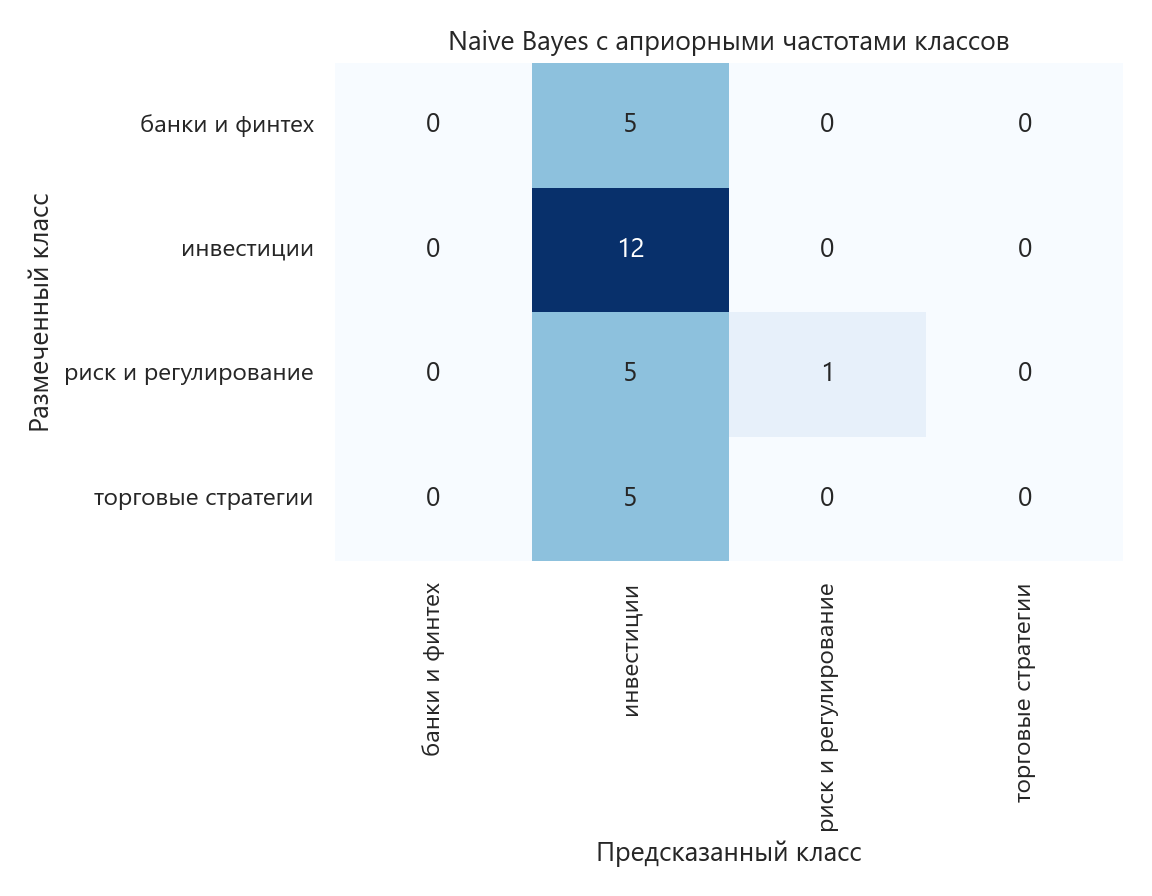

C:\Users\Атамырат\AppData\Local\Temp\ipykernel_21148\3884112074.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


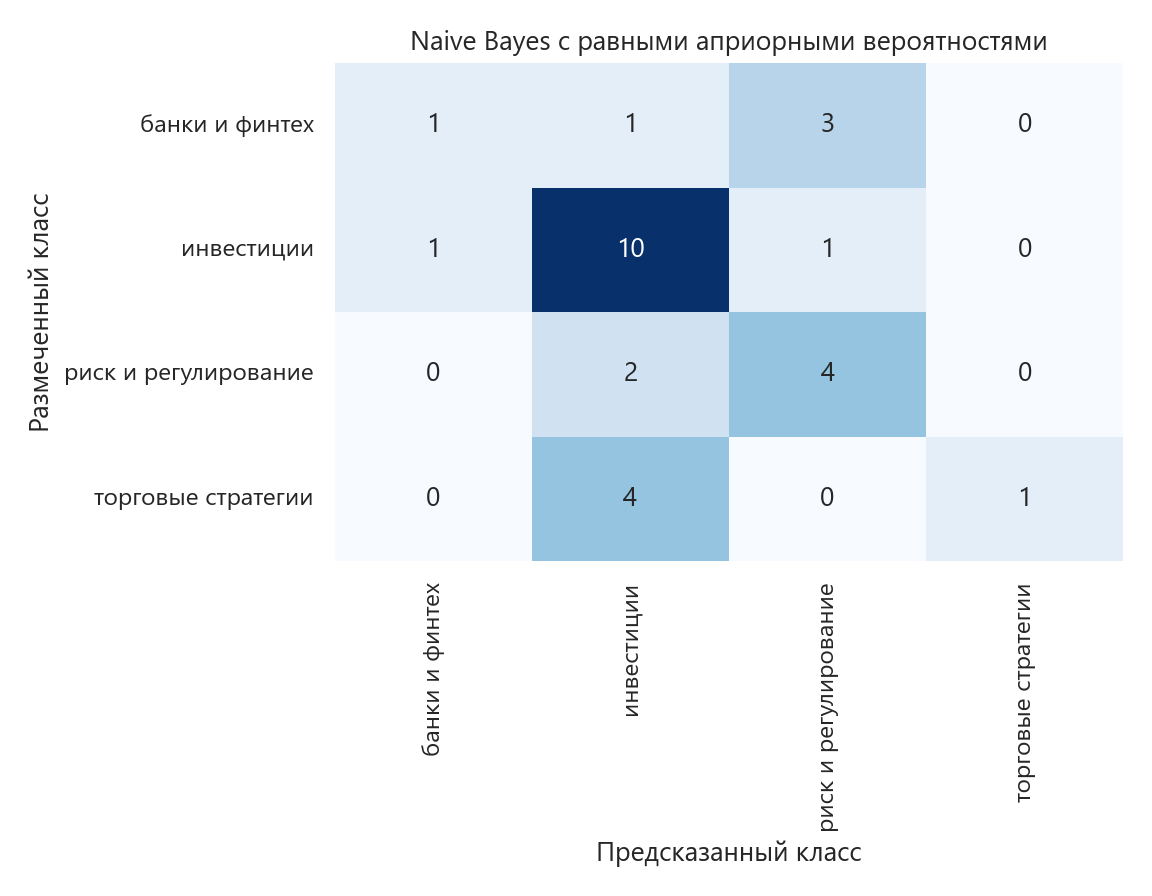

C:\Users\Атамырат\AppData\Local\Temp\ipykernel_21148\3884112074.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


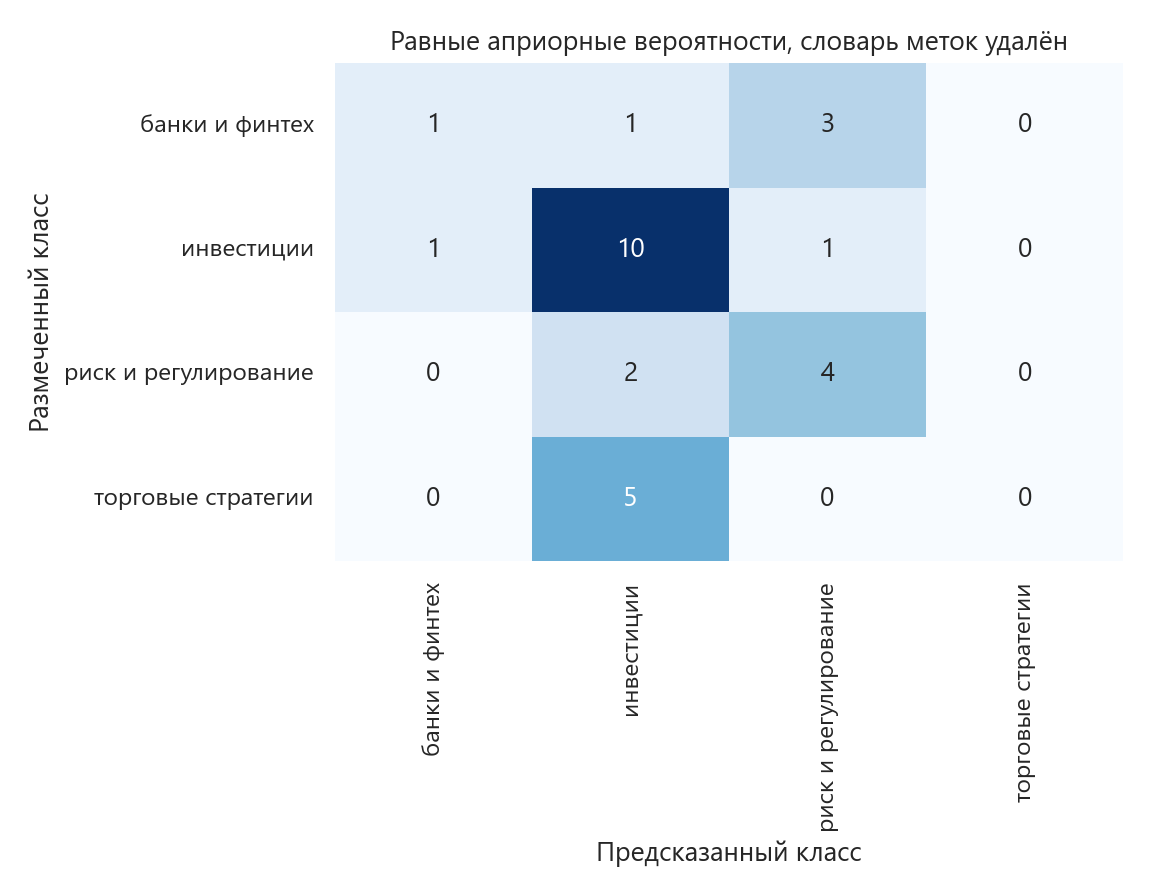

In [11]:
def show_matrix(result, title):
    labels = [names_ru.get(code, code) for code in result["labels"]]
    fig, ax = plt.subplots(figsize=(7.2, 5.6))
    sns.heatmap(
        result["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        cbar=False,
    )
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Размеченный класс")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

show_matrix(full, "Априорные частоты классов")
display(Image(filename=str(ROOT / "figures" / "confusion_full.png")))
show_matrix(balanced, "Равные априорные вероятности")
display(Image(filename=str(ROOT / "figures" / "confusion_balanced.png")))
show_matrix(masked, "Словарь меток удалён")
display(Image(filename=str(ROOT / "figures" / "confusion_masked.png")))


Как читать матрицу. Строка — класс, который поставило правило. Столбец — класс, который выбрала модель. Диагональ — совпадения. Числа маленькие: в тесте 28 статей, и пять торговых статей на проверке означают, что одна ошибка сильно двигает F1 этого класса. Цифры годятся, чтобы сравнить три постановки между собой, и не годятся как промышленная оценка.

Что видно на текущем корпусе. При априорных частотах accuracy близка к константе «всегда инвестиции», а macro-F1 низкий: инвестиции получают полный recall, банки и торговля почти не узнаются. При равных априорных вероятностях классы расходятся. Лучше всего отделяются инвестиции, затем риск. Банки остаются слабым классом. После удаления словаря меток риск держит тот же F1 по соседнему контексту (проверки, мошенничество, регулятор), а торговля на этом прогоне не узнаётся: часть её сигнала сидела в самих словах `algorithmic trading` и `machine learning`.


## 8. Выводы по варианту

По собранному корпусу разговор об ИИ в финансах не собран вокруг компьютерного зрения. Глубокое обучение после добавления аннотаций arXiv видно шире, чем в одних колонках Forbes: это язык научных аннотаций, а не деловой ленты. Шире всего по-прежнему риск, затем генеративный ИИ и машинное обучение. Алгоритмическая торговля есть и в прессе, и в arXiv, но не задаёт весь корпус.

Четыре линии совпадают с классами разметки.

- Торговля: автоматизация заявок и вопрос, остаётся ли у человека контроль над алгоритмом.
- Инвестиции: портфель, акции компаний, связанных с ИИ, сравнение модели с управляющим.
- Банки и финтех: кредитование, платежи, внутренние помощники, команды, которые сопровождают модели.
- Риск: мошенничество, кредитные решения, надзор, проверка того, что модель делает в работе. По частоте это самая настойчивая линия.

Генеративный ИИ в этих текстах — инструмент сотрудника и клиента, а не замена торгового движка. Внедрение большой языковой модели в банк и алгоритмическая торговля — разные проекты с разными рисками, хотя заголовки называют и то и другое «ИИ на рынке».

Наивный Байес это различение подтверждает частично. При равных априорных вероятностях он обыгрывает константу «всегда инвестиции». Лучше всего отделяются инвестиции, затем риск. Риск держится и после удаления слов размечающего словаря. Торговля на контрольном прогоне проседает, класс «банки» отделяется плохо. Для мониторинга ленты достаточно автоматически ловить риск, а границу «банк, инвестиции или торговля» лучше оставлять человеку.

Практическое ограничение прямое. По этим статьям нельзя выбрать параметры стратегии, одобрить кредит или сделать регуляторный вывод: нет цен, нет горизонта, нет ответственности за ошибку. Forbes здесь — карта повестки. Часть материалов — колонки Forbes Councils, то есть мнение приглашённого автора, иногда с коммерческим интересом. Следующий шаг, если продолжать работу: разметить 200–300 статей вручную, отделить колонки от новостей и посчитать долю генеративного ИИ и долю алгоритмической торговли по годам.


## 9. Где лежат файлы и как повторить сбор

| Файл | Что в нём |
|---|---|
| `collect.py` | RSS, адрес Forbes, текст страницы или снимка, фильтр заголовков |
| `collect_extra.py` | аннотации arXiv (q-fin) и полные статьи TechCrunch, без замены более длинного текста |
| `fill_bodies.py` | добивка полного текста для записей, которые остались с одним заголовком |
| `analyze.py` | те же функции частот, TF-IDF и Байеса, плюс сохранение `results/summary.json` и графиков |
| `data/publications.json`, `data/publications.csv` | дата, заголовок, адрес, источник текста, сам текст |
| `build_report.py` | пояснительная записка docx по посчитанному `summary.json` |

Повторный сбор, если нужна новая выгрузка:

```python
# из папки RGR_variant4, в сети, несколько минут
# %run collect.py
# %run fill_bodies.py
# %run collect_extra.py
```

Эти команды в ноутбуке не запускаются сами: они заново ходят на Forbes, в архив, на arXiv и TechCrunch. Расчёт выше читает уже собранный файл и поэтому повторяется без сети.
